Shape after cleaning: (900, 21) (900,)
Target variable being used: log_streams
--------------------------------------------------
Train shape: (720, 21)  (y target is log-transformed)
Test shape: (180, 21)  (y target is log-transformed)

Log-Linear Regression Performance
-----------------------------------
R² Score (Log Scale): 0.5122
MAE (Original Streams): 259,419,392.78
RMSE (Original Streams): 868,603,467.79
-----------------------------------
Note: MAE/RMSE are back-transformed to be in 'number of streams'.


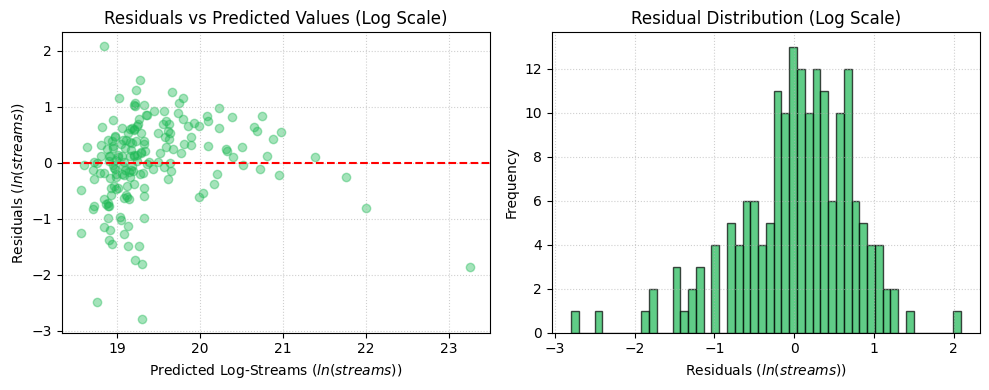

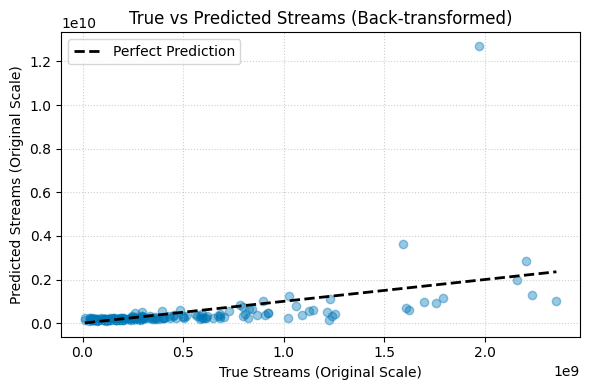

In [5]:
# 4.2.1 Data Preparation (Minimal Preprocessing)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# 1. Load dataset (with encoding)
# Using contentFetchId to access the uploaded file
df = pd.read_csv("spotify_initial_prepared.csv", encoding="latin1")

# ==============================================================================
# 2. Define the new target column for log-transformation
# The original streams column is named 'streams'. We will now use log(1 + streams).
# ==============================================================================
TARGET = "log_streams" # New target is the log-transformed stream count

# 3. Identify text and categorical columns
text_cols = ["track_name", "artist(s)_name"]
cat_cols = ["key", "mode"]

# 4. Treat all remaining columns as numeric (except text + categorical + original streams)
EXCLUDE_COLS = text_cols + cat_cols + ["streams"] # Exclude original 'streams' column as well
numeric_cols = [c for c in df.columns if c not in EXCLUDE_COLS]

# 5. Clean numeric columns: remove commas and convert to float
for col in numeric_cols:
    if col in df.columns:
        df[col] = (
            df[col]
            .astype(str)
            .str.replace(",", "", regex=False)  # "2,163" → "2163"
        )
        # Use errors='coerce' to turn any remaining unconvertible values into NaN
        df[col] = pd.to_numeric(df[col], errors="coerce")

# 6. Label-encode categorical columns: key, mode
label_encoders = {}
for col in cat_cols:
    if col in df.columns:
        le = LabelEncoder()
        # Fit on string representation to handle potential mixed types/NaN
        df[col] = le.fit_transform(df[col].astype(str))
        label_encoders[col] = le

# 7. Drop rows where the new log target is missing
df = df.dropna(subset=[TARGET])

# 8. Build X and y
# Drop text columns, and the original 'streams' column (since we are using log_streams)
drop_cols = text_cols + ["streams", TARGET]
existing_drop_cols = [c for c in drop_cols if c in df.columns]

X = df.drop(columns=existing_drop_cols)
y = df[TARGET]

# 9. Drop any remaining NaN rows from X
# This is important after cleaning numeric columns that might have coerced non-numbers to NaN
mask = X.notna().all(axis=1)
X = X[mask]
y = y[mask]

print("Shape after cleaning:", X.shape, y.shape)
print(f"Target variable being used: {TARGET}")
print("-" * 50)

# 10. Train-test split
X_train, X_test, y_train_log, y_test_log = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Train shape:", X_train.shape, " (y target is log-transformed)")
print("Test shape:", X_test.shape, " (y target is log-transformed)")


# 4.2.2 & 4.2.3 Baseline Linear Regression on Log-Streams
lin_reg = LinearRegression()
# Training on the log-transformed target (y_train_log)
lin_reg.fit(X_train, y_train_log)


# 4.2.4 Results — Performance + Residual Plots
# Predictions are in the log scale
y_pred_log = lin_reg.predict(X_test)

# ==============================================================================
# 11. # 'log_streams' is log(1 + streams), computed via np.log1p(streams)
# ==============================================================================
y_test_original = np.expm1(y_test_log)
y_pred_original = np.expm1(y_pred_log)

# Metrics (Calculated on the original scale for MAE/RMSE, except R-squared)
# R-squared is best interpreted on the transformed (log) scale.
r2_log_scale = r2_score(y_test_log, y_pred_log)
mae_original = mean_absolute_error(y_test_original, y_pred_original)
rmse_original = mean_squared_error(y_test_original, y_pred_original) ** 0.5

print("\nLog-Linear Regression Performance")
print("-----------------------------------")
# R-squared is reported on the log scale, indicating variance explained of log(streams)
print(f"R² Score (Log Scale): {r2_log_scale:.4f}")
# MAE/RMSE are reported on the original stream scale
print(f"MAE (Original Streams): {mae_original:,.2f}")
print(f"RMSE (Original Streams): {rmse_original:,.2f}")
print("-----------------------------------")
print("Note: MAE/RMSE are back-transformed to be in 'number of streams'.")


# Residuals for plotting should be calculated on the log scale
# The model is fit to minimize residuals on the log scale, so this is the relevant view.
residuals_log = y_test_log - y_pred_log

# Residual plot (Log Scale)
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.scatter(y_pred_log, residuals_log, alpha=0.4, color='#1DB954')
plt.axhline(0, linestyle="--", color='red')
plt.xlabel("Predicted Log-Streams ($ln(streams)$)")
plt.ylabel("Residuals ($ln(streams)$)")
plt.title("Residuals vs Predicted Values (Log Scale)")
plt.grid(True, linestyle=':', alpha=0.6)


# Residual distribution (Log Scale)
plt.subplot(1, 2, 2)
plt.hist(residuals_log, bins=50, color='#1DB954', edgecolor='black', alpha=0.7)
plt.xlabel("Residuals ($ln(streams)$)")
plt.ylabel("Frequency")
plt.title("Residual Distribution (Log Scale)")
plt.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

# Optional: Plot the original streams vs predicted streams (on original scale)
plt.figure(figsize=(6,4))
plt.scatter(y_test_original, y_pred_original, alpha=0.4, color='#0077B6')
plt.plot([y_test_original.min(), y_test_original.max()], [y_test_original.min(), y_test_original.max()], 'k--', lw=2, label="Perfect Prediction")
plt.xlabel("True Streams (Original Scale)")
plt.ylabel("Predicted Streams (Original Scale)")
plt.title("True vs Predicted Streams (Back-transformed)")
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()